# Robustness to nuisance parameters

The Fisher $\sigma_{A_B}$ and $\chi^2_{\min}$ of the bias analysis hold for a fixed geometry and a phase curve without further terms. A real analysis marginalises over the transit geometry and usually fits ellipsoidal terms. Every such nuisance is one more column of the same linear least-squares problem (`simple_bias_analysis`, "Robustness to nuisance parameters"), linearised around the noiseless $A_B$-only fit in whitened units, each column with its mean removed per detector (the free baseline):
$$\delta = \arg\min\ \lVert r_\perp - X\delta\rVert^2 + \sum_\nu (\delta_\nu/\sigma_{p,\nu})^2, \qquad {\rm Cov} = (X^{\sf T}X + \Lambda)^{-1},$$
with $r_\perp$ the residual of the $A_B$-only fit, $X = [j_A, j_{\nu_1}, \dots]$, $j = \partial m_{\rm ps}/\partial\theta/\sigma_{\rm bin}$, and a Gaussian prior on a nuisance as a penalty row (a flat prior adds none). From it: $\sigma_{A_B} = \sqrt{{\rm Cov}_{AA}}$, the shifted fit $\hat A_B + \delta_A$, the new minimum $\chi^{2\prime}_{\min}$, and per nuisance the shrinkage $\sigma_{\rm post}/\sigma_{\rm prior}$ (1: the data add nothing to the prior). If the extended-source model carries the same nuisances with the same priors, $\langle\ln B\rangle \approx \chi^{2\prime}_{\min}/2$ to first order (the determinant terms cancel).

**The columns.**
- **Geometry** $a/R_\star$, $R_p/R_\star$, $i$: central differences of the point-source model, each with a Gaussian prior from the planet's discovery paper. The transit and the occultation are part of the model (`transit=True`), so their shape constrains the geometry as well; the shrinkage shows by how much. The priors are independent: the published $a/R_\star$–$i$ correlation is ignored.
- **Stellar ellipsoidal variation**: the planet stretches the star. $-\cos 4\pi\phi$ in ppm, in every bin including the occultation (the star stays visible), one free amplitude per detector (limb and gravity darkening depend on the band), flat prior.
- **Planetary tidal deformation**: the planet's own elongation along the star–planet axis changes its projected area. $F_{p}(\phi)\,(1 - \sin^2 i\,\cos^2 2\pi\phi)$ with $F_p$ the point-source planet flux at the fitted $A_B$; one amplitude shared by all detectors (it is geometric), flat prior. It vanishes during the occultation, like the difference between the two irradiation models.

Only the $A_B$-only fit: the fit with redistribution sits at its $F = 0$ edge, where nothing linear in $F$ is trustworthy.

In [1]:
import numpy as np
import pandas as pd
import contextlib, io
import matplotlib.pyplot as plt
from dataclasses import replace
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
from simple_bias_analysis import *
from HItargets_utils import *
from paper_plot_utils import paper_figure, paper_theme

set_plot_style()

In [2]:
# Baseline settings (HItargets_utils.py)
A_B_true = DEFAULT_A_B
A_model = ConstantBandAlbedo(DEFAULT_A)
u, u_B = DEFAULT_U, DEFAULT_U_B
n_orbits, n_bins = DEFAULT_N_ORBITS, DEFAULT_N_BINS
kw = dict(n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)

# Planets and modes: MIRI/LRS, the joint NIRSpec fit, and all three detectors jointly (a tuple = one joint fit: shared A_B, a baseline per detector)
LRS, NRS1, NRS2 = "MIRI/LRS", *JWST_BANDS[:2]
MODES = {"MIRI/LRS": LRS, "joint NIRSpec": (NRS1, NRS2), "NIRSpec + LRS": (NRS1, NRS2, LRS)}
PLANETS = ("TOI-2431 b", "K2-141 b")

# Gaussian priors on the geometry (1 sigma), centred on the adopted values. a/R* and Rp/R* are EXACTLY the priors of the free-geometry dynesty runs
# (Dynesty Fits/more runs/*_freegeom_*.py), so the "+ (a/R*, Rp/R*)" row is the prediction for those runs. Independent priors: the published a/R*-i correlation is ignored.
PRIORS = {
    "TOI-2431 b": dict(a_rs=0.04,       # Tas et al. 2026 (A&A 707, A238): a/R* = 2.05 +- 0.04 from the fitted stellar density (2.08 adopted from a and R*)
                       rp_rs=0.00033,   # Tas et al. 2026 Tab. 2: 0.02131 +0.00033/-0.00032
                       incl=1.0),       # Tas et al. 2026 Tab. 2 (FCO fit): i = 74.0 +0.99/-0.96 deg (arXiv:2507.08464v1)
    "K2-141 b":   dict(a_rs=0.057,      # Malavolta et al. 2018 (AJ 155, 107) Tab. 3: 2.292 +0.053/-0.060, symmetrised
                       rp_rs=0.00046,   # Malavolta et al. 2018 Tab. 3: 0.02037 +- 0.00046
                       incl=3.15),      # Malavolta et al. 2018 Tab. 3: i = 86.3 +2.7/-3.6 deg, symmetrised (the upper error reaches i = 89, so the prior is not cut at 90)
}

# Rows of the table: which nuisances are free in addition to A_B and the baseline(s)
GEOM = ("a_rs", "rp_rs", "incl")
ROWS = {"fixed": (), "+ a/R*": ("a_rs",), "+ Rp/R*": ("rp_rs",), "+ i": ("incl",), "+ (a/R*, Rp/R*)": ("a_rs", "rp_rs"), "+ all geometry": GEOM,
        "+ stellar": ("stellar",), "+ planetary": ("planetary",), "+ geometry + stellar": (*GEOM, "stellar"), "+ geometry + planetary": (*GEOM, "planetary"),
        "+ geometry + stellar + planetary": (*GEOM, "stellar", "planetary")}

# Template cfg: band, planet and noise are replaced per case (retrieval_cfg)
l1, l2 = filter_lambda(LRS)
cfg = FittingConfig(planet=hi_planets_by_name(PLANETS[0]), filter_path=filter_loc(LRS), l1=l1, l2=l2, A_=A_model, sigma_1min=100., n_orbits=n_orbits, n_bins=n_bins, reflected=True, u_B=u_B, u=u)

## 1. The table

One linear problem per planet and mode (`nuisance_problem`: the noiseless truth, the $A_B$-only fit and every column), solved for each row of `ROWS` (`nuisance_table`). Columns: $\sigma_{A_B}$, the bias $\Delta A_B$ of the shifted fit and $|\Delta A_B|/\sigma_{A_B}$, $\chi^{2\prime}_{\min}$ and $\langle\ln B\rangle = \chi^{2\prime}_{\min}/2$; `shrink <name>` is $\sigma_{\rm post}/\sigma_{\rm prior}$ of a geometry parameter; for the flat-prior amplitudes the fitted value and its $\sigma$ are listed instead (`stellar:<k>` in ppm for detector $k$ of the mode, `planetary` as a fraction of the projected area). The fitted amplitudes are what the point-source model would attribute to the ellipsoidal term although the truth has none.

What to look for:
- **Geometry.** How much $\sigma_{A_B}$ grows and the significance $|\Delta A_B|/\sigma_{A_B}$ drops once the geometry is marginalised, and which parameter does it: $R_p/R_\star$ scales the planet's flux like $A_B$ does, and $a/R_\star$ enters the energy balance through $(1-A_B)(R_\star/a)^2$. A shrinkage well below 1 means the phase curve itself (transit and occultation shape) measures the parameter better than the prior. $\chi^{2\prime}_{\min}$, i.e. the evidence, should hardly move: the residual of the fit is not a geometry-like pattern.
- **$i$ free or fixed.** Compare `+ (a/R*, Rp/R*)` (the free-geometry dynesty runs, $i$ fixed) with `+ all geometry`: the shrinkage of $a/R_\star$ with $i$ fixed against $i$ free shows how much the fixed inclination pins the geometry, and the two $\sigma_{A_B}$ whether that matters for the albedo.
- **Ellipsoidal terms.** Both have the $-\cos 4\pi\phi$ shape of the residual. How much of $\chi^2_{\min}$ each absorbs, the amplitude it needs for that (compare with the expected physical amplitudes of section 3), and what it does to the bias: the planetary term is nearly a rescaling of the planet's flux between quadrature and conjunction and therefore degenerate with $A_B$.

In [3]:
def case(name, mode):
    '''The nuisance problem of one planet in one mode: its own geometry and noise, the noiseless hyperillumination truth, every column.'''
    pl = hi_planets_by_name(name)
    c = retrieval_cfg(cfg, pl, MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return nuisance_problem(c, truth, priors=PRIORS[name], **kw)

CASES = [(name, mode) for name in PLANETS for mode in MODES]
PROBLEMS = dict(zip(CASES, pmap(case, CASES)))
TABLES = {k: nuisance_table(p, A_B_true, ROWS) for k, p in PROBLEMS.items()}
tab = pd.concat([t.assign(planet=k[0], mode=k[1]) for k, t in TABLES.items()], ignore_index=True)   # tidy: one row per planet, mode and nuisance row

for (name, mode), t in TABLES.items():
    p = PROBLEMS[(name, mode)]
    dets = [instrument_label(d, oneline=True) for d in detectors(MODES[mode])]
    print(f"{name}, {mode}  (A_B,fit = {p['A_B_fit']:.4f}; stellar amplitudes: " + ", ".join(f"{k + 1} = {d}" for k, d in enumerate(dets)) + ")")
    print(t.to_string(index=False, na_rep="", float_format=lambda v: f"{v:.3g}"), "\n")

TOI-2431 b, MIRI/LRS  (A_B,fit = 0.1402; stellar amplitudes: 1 = MIRI LRS)
                             row  sigma_A_B  bias_A_B  bias_sigma  chi2  lnB_mean  shrink a_rs  shrink rp_rs  shrink incl  stellar:1  sig stellar:1  planetary  sig planetary
                           fixed     0.0531   -0.0598        1.13  12.6      6.32                                                                                            
                          + a/R*     0.0554   -0.0493        0.89  12.2       6.1        0.218                                                                               
                         + Rp/R*     0.0735   -0.0481       0.654  12.6      6.29                      0.358                                                                 
                             + i     0.0543   -0.0531       0.977  12.3      6.15                                   0.244                                                    
                 + (a/R*, Rp/R*)     0.0739   -0.0524  

**Figure `nuisance_robustness`.** The same numbers for all rows: the significance of the albedo bias (top) and the expected evidence (bottom), one line per mode. The dashed lines mark $1\sigma$ and the evidence thresholds 2.5 and 5.

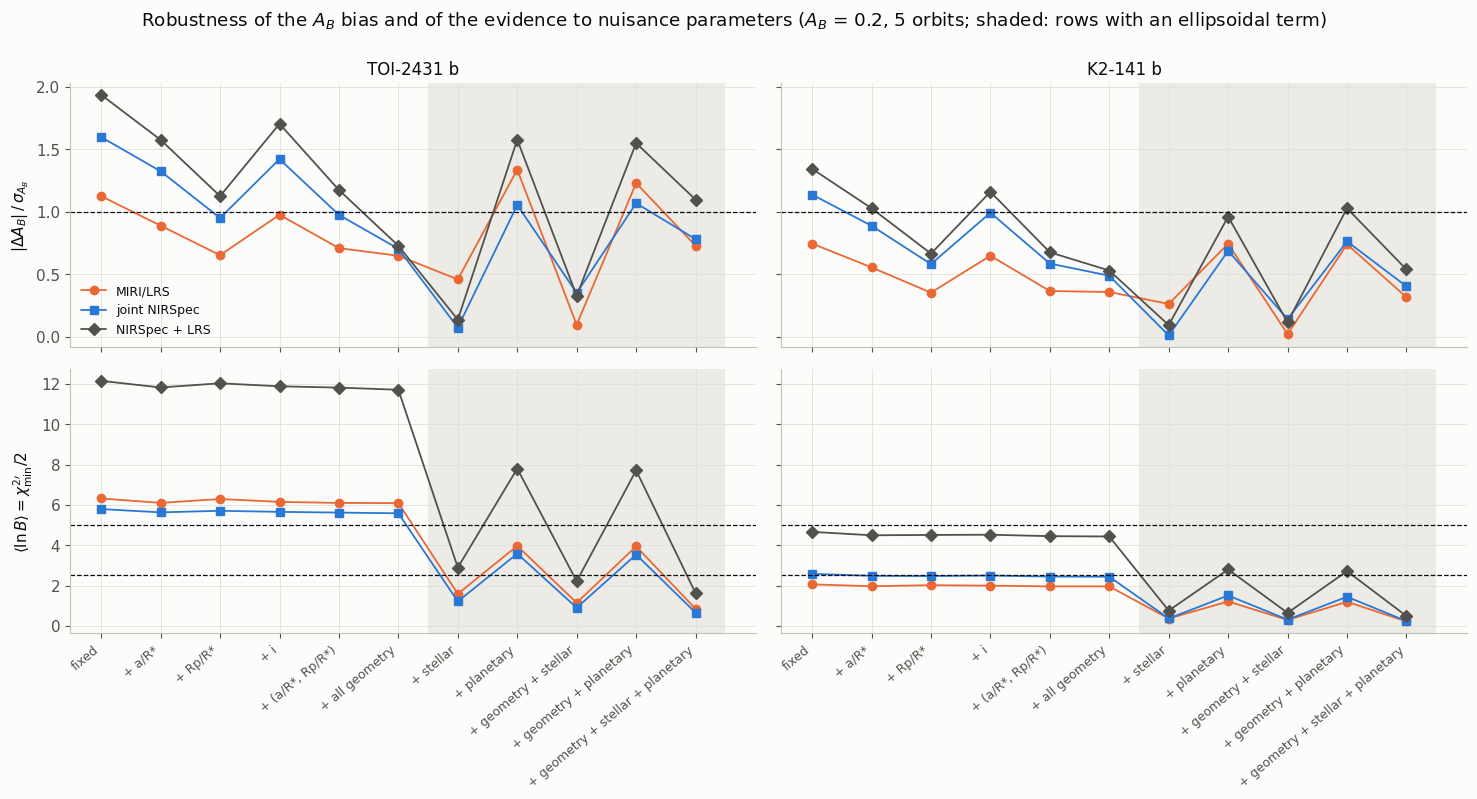

In [4]:
PAPER_MODE = False
fig, axs = plt.subplots(2, len(PLANETS), figsize=(7.5 * len(PLANETS), 8.), sharex=True, sharey="row", squeeze=False)
x = np.arange(len(ROWS))
for j, name in enumerate(PLANETS):
    for (mode, col), mk in zip(zip(MODES, (C_HI, C_REDIST, INK_2)), "osD"):
        t = TABLES[(name, mode)]
        axs[0, j].plot(x, t["bias_sigma"], mk + "-", color=col, lw=1.3, ms=6, label=mode)
        axs[1, j].plot(x, t["lnB_mean"], mk + "-", color=col, lw=1.3, ms=6, label=mode)
    axs[0, j].axhline(1., color=INK, lw=.9, ls="--")
    for lv in (2.5, 5.): axs[1, j].axhline(lv, color=INK, lw=.9, ls="--")
    axs[0, j].set_title(name); axs[1, j].set_xticks(x, list(ROWS), rotation=40, ha="right", fontsize=9)
    for a_ in axs[:, j]: a_.axvspan(5.5, len(ROWS) - 0.5, color="#ecebe6", lw=0, zorder=0)   # rows with an ellipsoidal term
axs[0, 0].set_ylabel(r"$|\Delta A_B|\,/\,\sigma_{A_B}$"); axs[1, 0].set_ylabel(r"$\langle\ln B\rangle = \chi^{2\prime}_{\min}/2$")
axs[0, 0].legend(fontsize=9)
fig.suptitle(rf"Robustness of the $A_B$ bias and of the evidence to nuisance parameters ($A_B$ = {A_B_true:g}, {n_orbits} orbits; shaded: rows with an ellipsoidal term)", y=0.995)
fig.tight_layout()
paper_figure("nuisance_robustness", PAPER_MODE, fig=fig)
plt.show()

## 2. Why the ellipsoidal terms absorb the evidence

The whitened residual $r_\perp$ of the $A_B$-only fit next to the two ellipsoidal columns, each scaled by its own best-fit amplitude (fitted alone, with $A_B$ and the baseline). The cosines between the vectors are printed: $\cos^2$ of the angle between $r_\perp$ and a column is the share of $\chi^2_{\min}$ that the column takes directly, before $A_B$ readjusts; the cosine between a column and the $A_B$ response $j_A$ is its degeneracy with the albedo.

What to look for: the in-occultation level of $r_\perp$. Both irradiation models are zero there, so it is only the fitted baseline, and it has the sign of $-\cos 4\pi\phi$ at $\phi = 0.5$. The stellar term, present during the occultation, therefore matches the residual there as well. The planetary term is zero inside the occultation (in the figure a constant, since every column has its mean removed like the residual) and overlaps with the albedo response outside it.

TOI-2431 b, MIRI/LRS: cos(r_perp, stellar) = +0.76, cos(r_perp, planetary) = +0.30, cos(stellar, planetary) = +0.76, cos(j_A, stellar) = -0.47, cos(j_A, planetary) = -0.87
TOI-2431 b, joint NIRSpec: cos(r_perp, stellar) = +0.77, cos(r_perp, planetary) = +0.30, cos(stellar, planetary) = +0.73, cos(j_A, stellar) = -0.45, cos(j_A, planetary) = -0.87


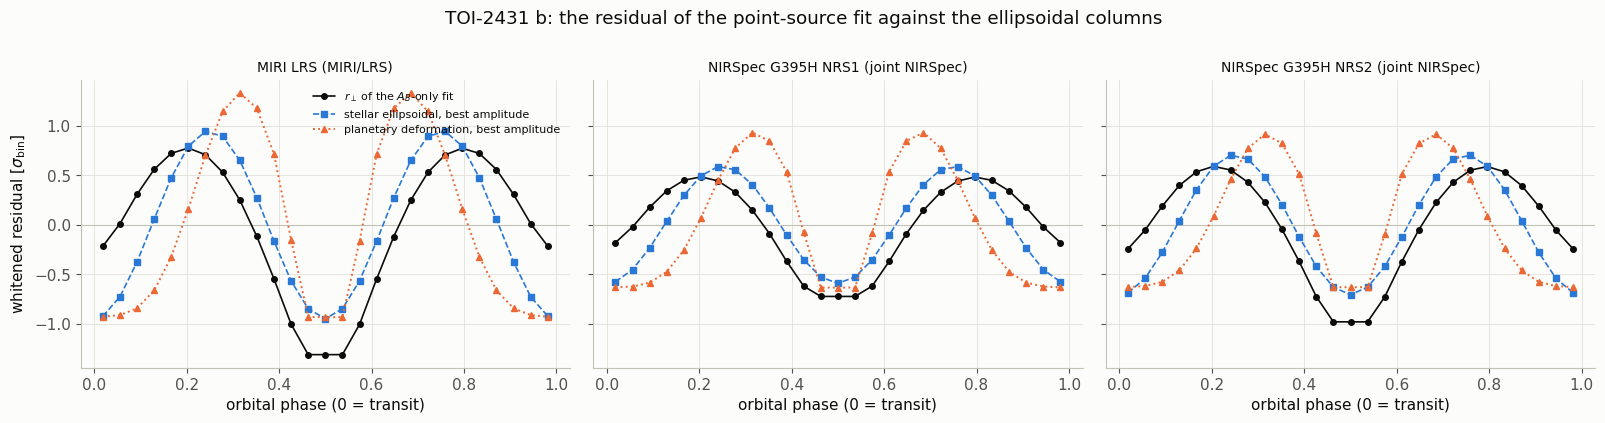

K2-141 b, MIRI/LRS: cos(r_perp, stellar) = +0.79, cos(r_perp, planetary) = +0.33, cos(stellar, planetary) = +0.78, cos(j_A, stellar) = -0.50, cos(j_A, planetary) = -0.86
K2-141 b, joint NIRSpec: cos(r_perp, stellar) = +0.79, cos(r_perp, planetary) = +0.33, cos(stellar, planetary) = +0.75, cos(j_A, stellar) = -0.48, cos(j_A, planetary) = -0.86


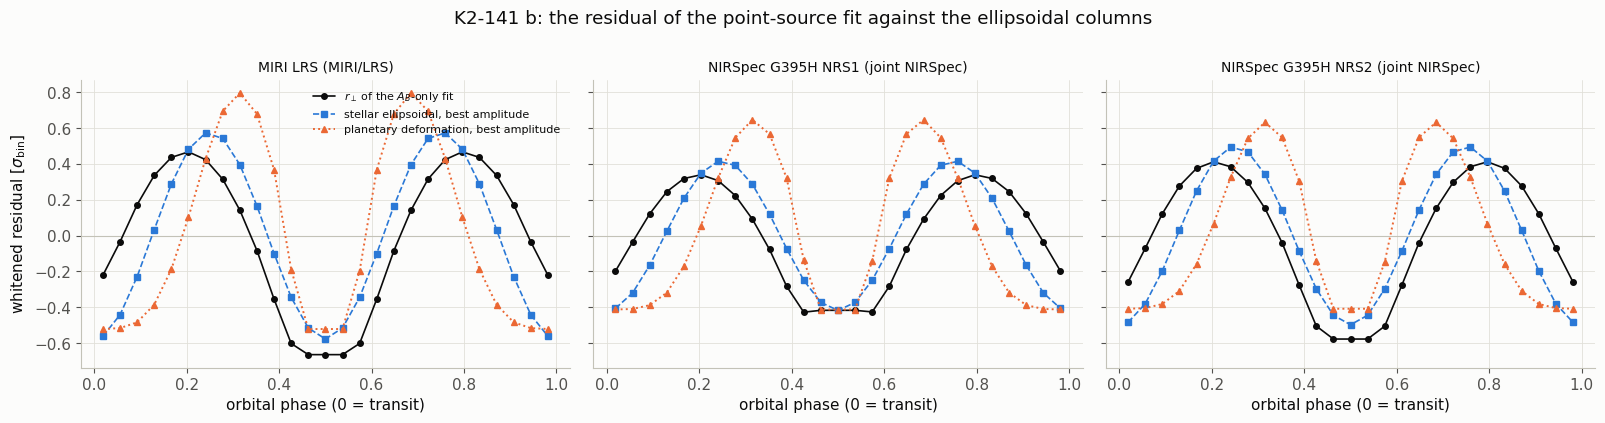

In [5]:
PAPER_MODE = False
cosang = lambda a, b: float(a @ b / np.linalg.norm(a) / np.linalg.norm(b))
for name in PLANETS:
    modes = [m for m in MODES if not m.startswith("NIRSpec +")]   # the three-detector set repeats the same blocks
    ncol = sum(len(PROBLEMS[(name, m)]["blocks"]) for m in modes)
    fig, axs = plt.subplots(1, ncol, figsize=(5.4 * ncol, 4.2), sharey=True, squeeze=False)
    k = 0
    for mode in modes:
        p = PROBLEMS[(name, mode)]
        s_st, s_pl = nuisance_solve(p, ("stellar",)), nuisance_solve(p, ("planetary",))
        y_st = sum(s_st["delta"][n] * p["columns"][n] for n in s_st["names"])
        y_pl = s_pl["delta"]["planetary"] * p["columns"]["planetary"]
        stellar_all = np.sum([p["columns"][n] for n in s_st["names"]], axis=0)   # all detectors with one amplitude, for the angles
        print(f"{name}, {mode}: cos(r_perp, stellar) = {cosang(p['y'], stellar_all):+.2f}, cos(r_perp, planetary) = {cosang(p['y'], p['columns']['planetary']):+.2f}, "
              f"cos(stellar, planetary) = {cosang(stellar_all, p['columns']['planetary']):+.2f}, cos(j_A, stellar) = {cosang(p['j_A'], stellar_all):+.2f}, cos(j_A, planetary) = {cosang(p['j_A'], p['columns']['planetary']):+.2f}")
        for blk, det in zip(p["blocks"], detectors(MODES[mode])):
            ax = axs[0, k]; k += 1
            ph = p["phase"][blk]
            ax.axhline(0., color=AXIS, lw=.8)
            ax.plot(ph, p["y"][blk], "o-", color=INK, lw=1.2, ms=4, label=r"$r_\perp$ of the $A_B$-only fit")
            ax.plot(ph, y_st[blk], "s--", color=C_REDIST, lw=1.2, ms=4, label="stellar ellipsoidal, best amplitude")
            ax.plot(ph, y_pl[blk], "^:", color=C_HI, lw=1.4, ms=4, label="planetary deformation, best amplitude")
            ax.set_title(f"{instrument_label(det, oneline=True)} ({mode})", fontsize=10); ax.set_xlabel("orbital phase (0 = transit)")
    axs[0, 0].set_ylabel(r"whitened residual [$\sigma_{\rm bin}$]"); axs[0, 0].legend(fontsize=8)
    fig.suptitle(f"{name}: the residual of the point-source fit against the ellipsoidal columns", y=1.0)
    fig.tight_layout()
    paper_figure(f"nuisance_columns_{name.replace(' ', '')}", PAPER_MODE, fig=fig)
    plt.show()

## 3. Expected physical amplitudes

For context, what the two ellipsoidal effects should amount to, against the amplitudes the fits of section 1 return.

**Star.** $A_{\rm ell} = \alpha_{\rm ell}\,(M_p/M_\star)\,(R_\star/a)^3\sin^2 i$ with $\alpha_{\rm ell} = 0.15\,(15 + u)(1 + g)/(3 - u)$ (Morris & Naftilan 1993; Shporer 2017, PASP 129, 072001), $u$ and $g$ the linear limb-darkening and the gravity-darkening coefficient of the band. The masses are published values (sources in the cell). **The band coefficients are not from a table yet**: the cell evaluates a bracket in $(u, g)$ that covers infrared values of K dwarfs, to be replaced by tabulated coefficients (e.g. Claret & Bloemen 2011, A&A 529, A75, Spitzer/IRAC bands). $\alpha_{\rm ell}$ depends on them only through $(15+u)/(3-u)$ and $(1+g)$.

**Planet.** The fitted `planetary` amplitude is the fractional change of the projected area between conjunction and quadrature, of the order of the planet's tidal elongation. Taş et al. (2026) quote the axis ratio of TOI-2431 b for a fiducial Love number $h_2 = 1$ (value in the cell).

What to look for: whether the amplitude a free ellipsoidal term needs to absorb the hyper-illumination residual is larger than, or comparable to, the physical one. If it is larger, a prior on the amplitude (the stellar one follows from the measured mass ratio) restores part of the evidence; the last lines repeat the `+ stellar` row with a Gaussian prior of width `STELLAR_PRIOR_FRAC` times the expected amplitude (the truth has no ellipsoidal term in either model, so the prior is centred on the truth).

In [6]:
M_EARTH_SUN = 3.0035e-6   # M_Earth / M_Sun (IAU 2015 nominal values)
MASSES = {"TOI-2431 b": (6.2, 1.2, 0.661),   # M_p [M_E], its 1 sigma, M_star [M_sun]: Tas et al. 2026 Tab. 1-2 (FCO fit; arXiv:2507.08464v1)
          "K2-141 b":   (5.08, 0.41, 0.708)}   # Malavolta et al. 2018 Tab. 2-3
U_RANGE, G_RANGE = (0.1, 0.3), (0.1, 0.4)    # bracket of the linear limb-darkening and gravity-darkening coefficients in the infrared (NOT from a table yet, see above)
AXIS_RATIO = {"TOI-2431 b": (0.087, 0.017)}  # (R1 - R3) / R1 for h2 = 1: Tas et al. 2026 (arXiv:2507.08464v1, Sect. on tidal deformation)
STELLAR_PRIOR_FRAC = 1.0                     # width of the stellar-amplitude prior of the last lines, as a fraction of the expected amplitude

for name in PLANETS:
    pl = hi_planets_by_name(name)
    Mp, sMp, Ms = MASSES[name]
    q = Mp * M_EARTH_SUN / Ms
    lo, hi = ellipsoidal_amplitude(pl, q, U_RANGE[0], G_RANGE[0]), ellipsoidal_amplitude(pl, q, U_RANGE[1], G_RANGE[1])
    mid = 0.5 * (lo + hi)
    print(f"{name}: M_p / M_star = {q:.3e} (+- {100 * sMp / Mp:.0f} % from M_p)  ->  expected stellar ellipsoidal semi-amplitude {lo:.2f}-{hi:.2f} ppm for u in {U_RANGE}, g in {G_RANGE}")
    if name in AXIS_RATIO: print(f"   published tidal axis ratio of the planet (h2 = 1): {AXIS_RATIO[name][0]:.3f} +- {AXIS_RATIO[name][1]:.3f}")
    for mode in MODES:
        p, t = PROBLEMS[(name, mode)], TABLES[(name, mode)].set_index("row")
        st = [c for c in t.columns if c.startswith("stellar:")]
        print(f"   {mode:14s} fitted alone: stellar " + ", ".join(f"{t.loc['+ stellar', c]:.1f} +- {t.loc['+ stellar', 'sig ' + c]:.1f}" for c in st) + f" ppm;  planetary {t.loc['+ planetary', 'planetary']:.3f} +- {t.loc['+ planetary', 'sig planetary']:.3f}")
        prior = {**p["priors"], **{c: STELLAR_PRIOR_FRAC * mid for c in st}}
        s = nuisance_solve({**p, "priors": prior}, ("stellar",))
        print(f"   {'':14s} + stellar with a prior of {STELLAR_PRIOR_FRAC:g} x {mid:.1f} ppm: sigma_A_B = {s['sigma_A_B']:.4f}, bias {s['A_B_fit'] - A_B_true:+.4f} ({abs(s['A_B_fit'] - A_B_true) / s['sigma_A_B']:.2f} sigma), "
              f"<ln B> = {s['lnB_mean']:.2f}  (flat prior: {t.loc['+ stellar', 'lnB_mean']:.2f}, no stellar term: {t.loc['fixed', 'lnB_mean']:.2f})")

TOI-2431 b: M_p / M_star = 2.817e-05 (+- 19 % from M_p)  ->  expected stellar ellipsoidal semi-amplitude 2.49-3.44 ppm for u in (0.1, 0.3), g in (0.1, 0.4)
   published tidal axis ratio of the planet (h2 = 1): 0.087 +- 0.017
   MIRI/LRS       fitted alone: stellar 7.8 +- 2.5 ppm;  planetary 0.145 +- 0.067
                  + stellar with a prior of 1 x 3.0 ppm: sigma_A_B = 0.0573, bias -0.0093 (0.16 sigma), <ln B> = 3.59  (flat prior: 1.59, no stellar term: 6.32)
   joint NIRSpec  fitted alone: stellar 3.0 +- 1.5, 4.6 +- 1.8 ppm;  planetary 0.099 +- 0.047
                  + stellar with a prior of 1 x 3.0 ppm: sigma_A_B = 0.0290, bias -0.0128 (0.44 sigma), <ln B> = 2.44  (flat prior: 1.21, no stellar term: 5.79)
   NIRSpec + LRS  fitted alone: stellar 3.1 +- 1.5, 4.7 +- 1.8, 7.3 +- 2.3 ppm;  planetary 0.110 +- 0.037
                  + stellar with a prior of 1 x 3.0 ppm: sigma_A_B = 0.0259, bias -0.0121 (0.47 sigma), <ln B> = 6.03  (flat prior: 2.89, no stellar term: 12.15)
K2-141 b:

## 4. Checks

**Step size of the geometry columns.** The same tables with every finite-difference step doubled (`NUISANCE_STEPS` × 2): the relative change of each column and the largest relative change of $\sigma_{A_B}$ and $\chi^{2\prime}_{\min}$ over all rows.

**Nonlinear refit.** For one case (`NL_CASE`), the full nonlinear least-squares fit (`nuisance_fit_nonlinear`: the point-source model re-evaluated at every step, priors as residual rows, baselines by mean removal) against the linear rows: $\hat A_B$, $\sigma_{A_B}$ from the Jacobian at the solution, and $\chi^2_{\min}$.

What to look for: the linear and the nonlinear numbers agree where the fit moves little (geometry rows). Where an ellipsoidal term shifts $A_B$ by more than its $\sigma$, the response to $A_B$ is no longer linear over the shift ($T \propto (1-A_B)^{1/4}$) and the two differ in $\hat A_B$ and $\sigma_{A_B}$, while $\chi^2_{\min}$, the quantity the evidence rests on, stays close.

In [7]:
def case_2h(name, mode):
    pl = hi_planets_by_name(name)
    c = retrieval_cfg(cfg, pl, MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return nuisance_problem(c, truth, priors=PRIORS[name], steps={k: 2. * v for k, v in NUISANCE_STEPS.items()}, **kw)

P2 = dict(zip(CASES, pmap(case_2h, CASES)))
print(f"steps {NUISANCE_STEPS} against twice these:")
for k in CASES:
    t1, t2 = TABLES[k], nuisance_table(P2[k], A_B_true, ROWS)
    cols = ", ".join(f"{n} {np.linalg.norm(PROBLEMS[k]['columns'][n] - P2[k]['columns'][n]) / np.linalg.norm(PROBLEMS[k]['columns'][n]):.1e}" for n in GEOM)
    print(f"   {k[0]:11s} {k[1]:14s} relative change of the columns: {cols};  max over rows: sigma_A_B {np.max(np.abs(t2['sigma_A_B'] / t1['sigma_A_B'] - 1.)):.1e}, chi2 {np.max(np.abs(t2['chi2'] / t1['chi2'] - 1.)):.1e}")

steps {'a_rs': 0.005, 'rp_rs': 0.0001, 'incl': 0.2} against twice these:
   TOI-2431 b  MIRI/LRS       relative change of the columns: a_rs 6.0e-03, rp_rs 1.6e-06, incl 1.7e-03;  max over rows: sigma_A_B 8.5e-04, chi2 9.2e-04
   TOI-2431 b  joint NIRSpec  relative change of the columns: a_rs 4.2e-03, rp_rs 1.3e-06, incl 1.5e-03;  max over rows: sigma_A_B 2.3e-03, chi2 1.1e-03
   TOI-2431 b  NIRSpec + LRS  relative change of the columns: a_rs 4.6e-03, rp_rs 1.4e-06, incl 1.6e-03;  max over rows: sigma_A_B 2.9e-03, chi2 1.5e-03
   K2-141 b    MIRI/LRS       relative change of the columns: a_rs 8.5e-03, rp_rs 1.1e-07, incl 2.9e-03;  max over rows: sigma_A_B 1.5e-04, chi2 3.2e-04
   K2-141 b    joint NIRSpec  relative change of the columns: a_rs 6.8e-03, rp_rs 6.7e-08, incl 2.2e-03;  max over rows: sigma_A_B 3.3e-04, chi2 4.5e-04
   K2-141 b    NIRSpec + LRS  relative change of the columns: a_rs 7.1e-03, rp_rs 7.5e-08, incl 2.3e-03;  max over rows: sigma_A_B 3.3e-04, chi2 5.2e-04


In [8]:
NL_CASE = ("TOI-2431 b", "MIRI/LRS")
NL_ROWS = ["+ (a/R*, Rp/R*)", "+ all geometry", "+ stellar", "+ planetary", "+ geometry + stellar", "+ geometry + planetary", "+ geometry + stellar + planetary"]

def nonlinear(label):
    pl = hi_planets_by_name(NL_CASE[0])
    c = retrieval_cfg(cfg, pl, MODES[NL_CASE[1]])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return nuisance_fit_nonlinear(c, truth, ROWS[label], priors=PRIORS[NL_CASE[0]], **kw)

NL = dict(zip(NL_ROWS, pmap(nonlinear, [(r,) for r in NL_ROWS])))
p = PROBLEMS[NL_CASE]
rows = []
for label, nl in NL.items():
    lin = nuisance_solve(p, ROWS[label])
    rows.append({"row": label, "A_B lin": lin["A_B_fit"], "A_B nonlin": nl["A_B_fit"], "sigma lin": lin["sigma_A_B"], "sigma nonlin": nl["sigma_A_B"], "chi2 lin": lin["chi2"], "chi2 nonlin": nl["chi2"], "nfev": nl["nfev"]})
print(f"{NL_CASE[0]}, {NL_CASE[1]}: linear rows against the nonlinear least-squares fit")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4g}"))
print("\nfitted nuisances, linear | nonlinear (value +- sigma):")
for label, nl in NL.items():
    lin = nuisance_solve(p, ROWS[label])
    print(f"   {label}: " + ";  ".join(f"{n} {p['values'].get(n, 0.) + lin['delta'][n]:.5g} +- {lin['sigma_post'][n]:.2g} | {nl['values'][n]:.5g} +- {nl['sigma_post'][n]:.2g}" for n in lin["names"]))

TOI-2431 b, MIRI/LRS: linear rows against the nonlinear least-squares fit
                             row  A_B lin  A_B nonlin  sigma lin  sigma nonlin  chi2 lin  chi2 nonlin  nfev
                 + (a/R*, Rp/R*)   0.1476      0.1467    0.07385       0.07346     12.19         12.2    14
                  + all geometry   0.1501      0.1487     0.0768        0.0762     12.18        12.19    14
                       + stellar   0.2277      0.2246    0.06022       0.05591     3.172        3.172    12
                     + planetary   0.3448      0.3276     0.1082       0.09136      7.93        7.954    23
            + geometry + stellar   0.1925      0.1919    0.07796       0.07462     2.284        2.284    16
          + geometry + planetary   0.3532      0.3349     0.1245         0.103      7.88        7.903    22
+ geometry + stellar + planetary  0.07871     0.07645     0.1663        0.1771     1.684        1.684    17

fitted nuisances, linear | nonlinear (value +- sigma):
   + (